# Bank Loan Portfolio & Credit Risk — Python Analysis

## Objective

This notebook analyzes the raw bank-loan dataset in Python and mirrors the business requirements from the Bank Loan Report problem statement.

The analysis covers:

- Portfolio KPIs: applications, funded amount, repayments, interest rate and DTI
- Good vs Bad Loan performance
- Loan-status analysis
- Monthly lending activity
- Regional/state analysis
- Loan-term analysis
- Home-ownership analysis
- Loan-purpose analysis
- Risk segmentation by grade
- Data-quality validation
- Business insights for lending decisions

> **Important:** The notebook calculates results directly from the raw file. It does not hard-code KPI values. Put your raw `Financial_loan_data.xlsx` file in the same folder as this notebook, or change `DATA_PATH` in the loading cell.

## 1. Import the Python libraries

**What are we doing?**

We load the libraries required for data analysis and visualization.

- `pandas` → reading and manipulating tabular loan data
- `numpy` → numerical calculations
- `matplotlib` → general plotting
- `seaborn` → statistical charts
- `plotly` → interactive treemap and U.S. state map

This is the foundation of the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Define the raw-data location and Loading the Data

**What are we doing?**

We keep the file location in one variable so the rest of the notebook does not need to repeat the path.

If your raw file has a different name or location, change only this cell.

The expected raw file is `Financial_loan_data.xlsx`.

In [3]:
import pandas as pd

# Updated file path to include the Python ETL script folder
df = pd.read_excel(
    r"C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\BANK LOAN ANALYTICS DASHBOARD END TO END PROJECT USING POWER BI\Python ETL script\Financial_loan_data.xlsx"
)

print(df.shape)
df.head()

(38576, 23)


,ISSUE_DATE,ID,PURPOSE,VERIFICATION_STATUS,GRADE,HOME_OWNERSHIP,ADDRESS_STATE,LOAN_STATUS,EMP_LENGTH,EMP_TITLE,LAST_CREDIT_PULL_DATE,LAST_PAYMENT_DATE,NEXT_PAYMENT_DATE,MEMBER_ID,SUB_GRADE,TERM,ANNUAL_INCOME,DTI,INSTALLMENT,INT_RATE,LOAN_AMOUNT,TOTAL_ACC,TOTAL_PAYMENT
0,2021-01-01,1072053,car,Source Verified,E,RENT,CA,Fully Paid,9 years,MKC Accounting,2021-12-14,2021-01-15,2021-02-15,1288686,E1,36 months,"48,000.00",0.05,109.43,0.19,3000,4,3939
1,2021-01-01,1068350,car,Verified,A,MORTGAGE,IL,Fully Paid,10+ years,J&J Steel Inc,2021-12-14,2021-01-15,2021-02-15,1302971,A1,36 months,"83,000.00",0.02,106.53,0.06,3500,28,3835
2,2021-01-05,1069243,car,Not Verified,C,RENT,CA,Charged Off,4 years,Chemat Technology Inc,2021-12-12,2021-01-09,2021-02-09,1304116,C5,36 months,"50,000.00",0.21,421.65,0.16,12000,11,3522
3,2021-01-08,207910,car,Not Verified,A,MORTGAGE,FL,Charged Off,< 1 year,NaN,2021-05-16,2021-02-10,2021-03-10,183496,A2,36 months,"120,000.00",0.08,69.14,0.07,2225,20,2508
4,2021-01-08,211723,car,Not Verified,C,OWN,MD,Charged Off,4 years,self employed,2021-12-09,2021-08-08,2021-09-08,211606,C2,36 months,"72,000.00",0.05,262.26,0.11,8000,8,2135


## 3. Inspect the first records

**What are we checking?**

`head()` gives us a quick view of the raw records.

At this stage we are not changing anything. We are simply understanding how one loan application is represented in the dataset.

In [7]:
display(df.head(10))

,ISSUE_DATE,ID,PURPOSE,VERIFICATION_STATUS,GRADE,HOME_OWNERSHIP,ADDRESS_STATE,LOAN_STATUS,EMP_LENGTH,EMP_TITLE,LAST_CREDIT_PULL_DATE,LAST_PAYMENT_DATE,NEXT_PAYMENT_DATE,MEMBER_ID,SUB_GRADE,TERM,ANNUAL_INCOME,DTI,INSTALLMENT,INT_RATE,LOAN_AMOUNT,TOTAL_ACC,TOTAL_PAYMENT
0,2021-01-01,1072053,car,Source Verified,E,RENT,CA,Fully Paid,9 years,MKC Accounting,2021-12-14,2021-01-15,2021-02-15,1288686,E1,36 months,"48,000.00",0.05,109.43,0.19,3000,4,3939
1,2021-01-01,1068350,car,Verified,A,MORTGAGE,IL,Fully Paid,10+ years,J&J Steel Inc,2021-12-14,2021-01-15,2021-02-15,1302971,A1,36 months,"83,000.00",0.02,106.53,0.06,3500,28,3835
2,2021-01-05,1069243,car,Not Verified,C,RENT,CA,Charged Off,4 years,Chemat Technology Inc,2021-12-12,2021-01-09,2021-02-09,1304116,C5,36 months,"50,000.00",0.21,421.65,0.16,12000,11,3522
3,2021-01-08,207910,car,Not Verified,A,MORTGAGE,FL,Charged Off,< 1 year,NaN,2021-05-16,2021-02-10,2021-03-10,183496,A2,36 months,"120,000.00",0.08,69.14,0.07,2225,20,2508
4,2021-01-08,211723,car,Not Verified,C,OWN,MD,Charged Off,4 years,self employed,2021-12-09,2021-08-08,2021-09-08,211606,C2,36 months,"72,000.00",0.05,262.26,0.11,8000,8,2135
5,2021-01-08,226154,car,Not Verified,E,MORTGAGE,MN,Fully Paid,10+ years,Ramsey County,2021-01-11,2021-02-11,2021-03-11,225530,E1,36 months,"72,000.00",0.23,170.72,0.14,5000,44,6146
6,2021-01-08,196380,car,Not Verified,A,RENT,CA,Fully Paid,10+ years,Comerica Bank,2021-02-10,2021-02-10,2021-03-10,188466,A4,36 months,"62,000.00",0.14,345.06,0.08,11000,23,12247
7,2021-01-08,206181,car,Not Verified,A,RENT,MA,Fully Paid,< 1 year,Lexington Alarm Systems,2021-04-16,2021-04-10,2021-05-10,167318,A1,36 months,"28,800.00",0.00,108.27,0.07,3500,5,3863
8,2021-01-08,219000,car,Not Verified,B,RENT,WA,Fully Paid,3 years,Evergreen Treatment Services,2021-01-11,2021-01-11,2021-02-11,218997,B1,36 months,"37,000.00",0.17,175.42,0.09,5500,36,6320
9,2021-01-08,222179,credit card,Not Verified,B,MORTGAGE,CO,Charged Off,4 years,"State of Colorado, WRRC",2021-05-16,2021-09-09,2021-10-09,222065,B1,36 months,"62,000.00",0.13,306.18,0.09,9600,51,5861


## 4. Inspect the last records

**Why?**

Checking the end of the dataset helps confirm that the file loaded completely and that the last records have the expected structure.

In [8]:
display(df.tail(10))

,ISSUE_DATE,ID,PURPOSE,VERIFICATION_STATUS,GRADE,HOME_OWNERSHIP,ADDRESS_STATE,LOAN_STATUS,EMP_LENGTH,EMP_TITLE,LAST_CREDIT_PULL_DATE,LAST_PAYMENT_DATE,NEXT_PAYMENT_DATE,MEMBER_ID,SUB_GRADE,TERM,ANNUAL_INCOME,DTI,INSTALLMENT,INT_RATE,LOAN_AMOUNT,TOTAL_ACC,TOTAL_PAYMENT
38566,2021-12-11,1055476,wedding,Source Verified,B,RENT,NJ,Fully Paid,1 year,Nomad Editorial,2021-12-14,2021-12-14,2022-01-14,1287029,B5,36 months,"75,000.00",0.04,281.78,0.13,8400,11,10144
38567,2021-12-11,1040347,wedding,Verified,C,RENT,FL,Fully Paid,< 1 year,Cross Country Staffing,2021-05-16,2021-08-13,2021-09-13,1270317,C3,36 months,"33,000.00",0.21,306.14,0.15,8875,29,9999
38568,2021-12-11,1046358,wedding,Source Verified,B,RENT,NY,Fully Paid,10+ years,The College of Westchester,2021-04-16,2021-11-14,2021-12-14,1277403,B5,60 months,"43,000.00",0.16,254.20,0.13,11250,15,14373
38569,2021-12-11,872910,wedding,Source Verified,B,RENT,NJ,Fully Paid,5 years,North Bergen Board of Education,2021-02-16,2021-02-16,2021-03-16,1087137,B4,60 months,"52,000.00",0.04,269.49,0.12,12000,11,16041
38570,2021-12-11,1036337,wedding,Source Verified,C,RENT,CA,Fully Paid,4 years,HireRight,2021-09-14,2021-09-14,2021-10-14,1266202,C2,60 months,"40,000.00",0.12,187.27,0.14,8000,26,10483
38571,2021-12-11,1048887,wedding,Verified,F,MORTGAGE,OH,Charged Off,2 years,"CINCINNATI CHILDREN""S HOSPITAL",2021-05-16,2021-05-12,2021-06-12,1280067,F3,60 months,"73,174.40",0.08,647.39,0.22,23600,17,24397
38572,2021-12-11,1036857,wedding,Verified,D,RENT,NY,Charged Off,10+ years,Supreme Court,2021-07-13,2021-03-13,2021-04-13,1266739,D5,60 months,"86,779.00",0.18,612.72,0.18,24000,35,9735
38573,2021-12-11,1026558,wedding,Verified,B,MORTGAGE,CA,Fully Paid,4 years,"ACCES I/O Products, Inc.",2021-10-14,2021-09-14,2021-10-14,1255948,B4,60 months,"54,600.00",0.12,561.44,0.12,25000,19,31693
38574,2021-12-11,1052169,wedding,Verified,C,RENT,NY,Fully Paid,1 year,Binder and Binder,2021-01-12,2021-01-12,2021-02-12,1283716,C1,60 months,"50,000.00",0.19,460.10,0.13,20000,39,20226
38575,2021-12-12,1059497,car,Verified,B,MORTGAGE,FL,Fully Paid,10+ years,Sandestin Beach Hilton,2021-12-14,2021-12-14,2022-01-14,1291322,B2,36 months,"35,000.00",0.14,162.87,0.11,5000,23,5863


## 5. Understand dataset size

**What are we measuring?**

We identify:

- Number of loan applications
- Number of raw columns

This gives the scale of the portfolio dataset before analysis.

In [9]:
rows, cols = df.shape

print("Number of loan applications:", f"{rows:,}")
print("Number of raw columns:", cols)

Number of loan applications: 38,576
Number of raw columns: 23


## 6. Review column names

**What are we doing?**

We list every raw field so we can map the data to the business questions in the problem statement.

Important fields include `ISSUE_DATE`, `LOAN_STATUS`, `GRADE`, `PURPOSE`, `ADDRESS_STATE`, `TERM`, `ANNUAL_INCOME`, `DTI`, `INT_RATE`, `LOAN_AMOUNT` and `TOTAL_PAYMENT`.

In [10]:
pd.DataFrame({"Column": df.columns})

,Column
0,ISSUE_DATE
1,ID
2,PURPOSE
3,VERIFICATION_STATUS
4,GRADE
5,HOME_OWNERSHIP
6,ADDRESS_STATE
7,LOAN_STATUS
8,EMP_LENGTH
9,EMP_TITLE


## 7. Check data types and non-null counts

**What are we checking?**

This tells us whether dates, numbers and categorical fields are stored correctly.

For example:

- Dates should be date/datetime values.
- Loan amount and payment should be numeric.
- Grade, purpose and loan status should be categorical/text values.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ISSUE_DATE             38576 non-null  datetime64[us]
 1   ID                     38576 non-null  int64         
 2   PURPOSE                38576 non-null  str           
 3   VERIFICATION_STATUS    38576 non-null  str           
 4   GRADE                  38576 non-null  str           
 5   HOME_OWNERSHIP         38576 non-null  str           
 6   ADDRESS_STATE          38576 non-null  str           
 7   LOAN_STATUS            38576 non-null  str           
 8   EMP_LENGTH             38576 non-null  str           
 9   EMP_TITLE              37138 non-null  object        
 10  LAST_CREDIT_PULL_DATE  38576 non-null  datetime64[us]
 11  LAST_PAYMENT_DATE      38576 non-null  datetime64[us]
 12  NEXT_PAYMENT_DATE      38576 non-null  datetime64[us]
 13  MEMBER_ID   

## 8. Statistical overview of numeric fields

**What are we doing?**

`describe()` provides count, mean, standard deviation, minimum, quartiles and maximum.

This helps us understand the overall financial profile of the loan portfolio and identify suspicious extreme values.

In [12]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,"38,576.00","681,037.06","211,324.58","54,734.00","513,517.00","662,728.00","836,506.00","1,077,501.00"
MEMBER_ID,"38,576.00","847,651.51","266,810.46","70,699.00","662,978.75","847,356.50","1,045,652.50","1,314,167.00"
ANNUAL_INCOME,"38,576.00","69,644.54","64,293.68","4,000.00","41,500.00","60,000.00","83,200.50","6,000,000.00"
DTI,"38,576.00",0.13,0.07,0.00,0.08,0.13,0.19,0.30
INSTALLMENT,"38,576.00",326.86,209.09,15.69,168.45,283.05,434.44,"1,305.19"
INT_RATE,"38,576.00",0.12,0.04,0.05,0.09,0.12,0.15,0.25
LOAN_AMOUNT,"38,576.00","11,296.07","7,460.75",500.00,"5,500.00","10,000.00","15,000.00","35,000.00"
TOTAL_ACC,"38,576.00",22.13,11.39,2.00,14.00,20.00,29.00,90.00
TOTAL_PAYMENT,"38,576.00","12,263.35","9,051.10",34.00,"5,633.00","10,042.00","16,658.00","58,564.00"


## 9. Check missing values

**Why is this important?**

Missing values can affect analysis.

We calculate both the number and percentage of missing records for every field. We do not delete records automatically; first we understand where the missingness occurs and whether the field is important for the required KPIs.

In [13]:
missing_summary = (
    pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": (df.isna().mean() * 100).round(2)
    })
    .sort_values("Missing_Count", ascending=False)
)

display(missing_summary[missing_summary["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
EMP_TITLE,1438,3.73


## 10. Visualize missing values

**What are we doing?**

A bar chart makes it easier to see whether missingness is concentrated in a small number of columns or spread throughout the dataset.

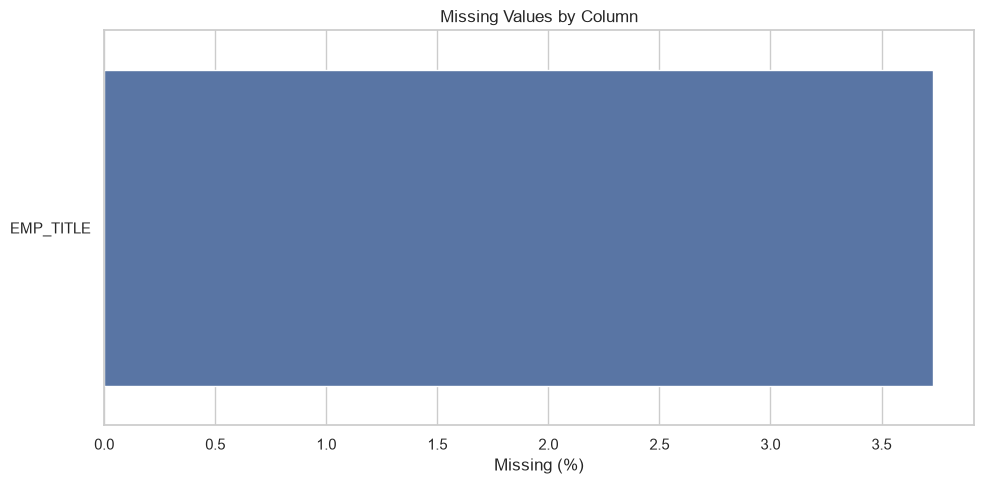

In [14]:
missing_plot = missing_summary[missing_summary["Missing_Count"] > 0].reset_index()
missing_plot.columns = ["Column", "Missing_Count", "Missing_Percentage"]

if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=missing_plot, x="Missing_Percentage", y="Column")
    plt.title("Missing Values by Column")
    plt.xlabel("Missing (%)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

## 11. Check duplicate records and duplicate loan IDs

**Why?**

The business metric "Total Loan Applications" assumes each loan application is represented correctly.

We therefore check:

- Entire duplicate rows
- Duplicate `ID`
- Duplicate `MEMBER_ID`

We do not remove duplicates automatically. First we quantify them.

In [15]:
duplicate_report = pd.Series({
    "Duplicate full rows": int(df.duplicated().sum()),
    "Duplicate loan IDs": int(df["ID"].duplicated().sum()) if "ID" in df.columns else np.nan,
    "Duplicate member IDs": int(df["MEMBER_ID"].duplicated().sum()) if "MEMBER_ID" in df.columns else np.nan
})

display(duplicate_report.to_frame("Count"))

,Count
Duplicate full rows,0
Duplicate loan IDs,0
Duplicate member IDs,0


## 12. Validate business-critical numeric fields

**What are we checking?**

Loan amount, DTI and interest rate should not contain negative values.

This is a business validation check rather than just a technical check.

In [16]:
checks = {
    "Negative loan amounts": int((df["LOAN_AMOUNT"] < 0).sum()),
    "Negative DTI": int((df["DTI"] < 0).sum()),
    "Negative interest rates": int((df["INT_RATE"] < 0).sum()),
    "Zero loan amounts": int((df["LOAN_AMOUNT"] == 0).sum())
}

display(pd.Series(checks, name="Count").to_frame())

,Count
Negative loan amounts,0
Negative DTI,0
Negative interest rates,0
Zero loan amounts,0


## 13. Standardize date fields

**What are we doing?**

The problem statement requires monthly trend analysis.

We explicitly convert date fields to datetime so that month/year calculations are reliable.

`errors="coerce"` turns invalid dates into missing values instead of crashing the entire workflow.

In [17]:
date_cols = [
    "ISSUE_DATE",
    "LAST_CREDIT_PULL_DATE",
    "LAST_PAYMENT_DATE",
    "NEXT_PAYMENT_DATE"
]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[date_cols].dtypes)

ISSUE_DATE               datetime64[us]
LAST_CREDIT_PULL_DATE    datetime64[us]
LAST_PAYMENT_DATE        datetime64[us]
NEXT_PAYMENT_DATE        datetime64[us]
dtype: object


## 14. Handle missing employment titles

**What are we doing?**

If `EMP_TITLE` has missing values, we label them `Unknown`.

We retain the loan applications because employment title is not required for the core portfolio KPIs such as funded amount, repayment, interest rate or DTI.

This avoids unnecessary loss of valid loan records.

In [18]:
if "EMP_TITLE" in df.columns:
    df["EMP_TITLE"] = df["EMP_TITLE"].fillna("Unknown")

print("Remaining missing EMP_TITLE values:",
      int(df["EMP_TITLE"].isna().sum()) if "EMP_TITLE" in df.columns else "Column not available")

Remaining missing EMP_TITLE values: 0


# Business Analysis

## 15. Create Good Loan / Bad Loan categories

**Business definition**

For this project:

- **Good Loan** = `Fully Paid` or `Current`
- **Bad Loan** = `Charged Off`

This classification is used consistently throughout the portfolio-risk analysis.

In [19]:
good_statuses = ["Fully Paid", "Current"]

df["LOAN_CATEGORY"] = np.where(
    df["LOAN_STATUS"].eq("Charged Off"),
    "Bad Loan",
    np.where(df["LOAN_STATUS"].isin(good_statuses), "Good Loan", "Other")
)

display(df["LOAN_CATEGORY"].value_counts(dropna=False).to_frame("Applications"))

,Applications
LOAN_CATEGORY,
Good Loan,33243
Bad Loan,5333


## 16. KPI — Total Loan Applications

**Business question:** How many loan applications are in the portfolio?

We count the loan application ID. If the ID is unique, this represents the total number of applications.

In [20]:
total_applications = df["ID"].nunique()
print(f"Total Loan Applications: {total_applications:,}")

Total Loan Applications: 38,576


## 17. KPI — Total Funded Amount

**Business question:** How much money did the bank fund?

We sum `LOAN_AMOUNT`.

This represents the amount disbursed/approved across the analyzed loan applications.

In [21]:
total_funded = df["LOAN_AMOUNT"].sum()
print(f"Total Funded Amount: ${total_funded:,.0f}")

Total Funded Amount: $435,757,075


## 18. KPI — Total Amount Received

**Business question:** How much has been received from borrowers?

We sum `TOTAL_PAYMENT`.

This is an important repayment and cash-flow indicator for the portfolio.

In [22]:
total_received = df["TOTAL_PAYMENT"].sum()
print(f"Total Amount Received: ${total_received:,.0f}")

Total Amount Received: $473,070,933


## 19. KPI — Average Interest Rate

**Business question:** What is the average interest rate charged across the portfolio?

The raw dataset stores `INT_RATE` as a decimal, so we multiply the average by 100 to display a percentage.

In [23]:
avg_interest_rate = df["INT_RATE"].mean() * 100
print(f"Average Interest Rate: {avg_interest_rate:.2f}%")

Average Interest Rate: 12.05%


## 20. KPI — Average DTI

**Business question:** What is the average borrower debt-to-income ratio?

`DTI` is stored as a decimal, so the average is multiplied by 100 for percentage presentation.

In [24]:
avg_dti = df["DTI"].mean() * 100
print(f"Average DTI: {avg_dti:.2f}%")

Average DTI: 13.33%


## 21. Create a single KPI table

**Why?**

A single table makes it easy to validate the numbers that should correspond to the Power BI Summary dashboard.

In [25]:
kpi_table = pd.DataFrame({
    "KPI": [
        "Total Loan Applications",
        "Total Funded Amount",
        "Total Amount Received",
        "Average Interest Rate",
        "Average DTI"
    ],
    "Value": [
        f"{total_applications:,}",
        f"${total_funded:,.0f}",
        f"${total_received:,.0f}",
        f"{avg_interest_rate:.2f}%",
        f"{avg_dti:.2f}%"
    ]
})

display(kpi_table)

,KPI,Value
0,Total Loan Applications,"38,576"
1,Total Funded Amount,"$435,757,075"
2,Total Amount Received,"$473,070,933"
3,Average Interest Rate,12.05%
4,Average DTI,13.33%


# Good vs Bad Loan Analysis

## 22. Good Loan vs Bad Loan application counts

**Business question:** What portion of applications are Good Loans versus Bad Loans?

This directly supports the Summary dashboard's Good Loan and Bad Loan visuals.

In [26]:
loan_category_counts = (
    df["LOAN_CATEGORY"]
    .value_counts()
    .reindex(["Good Loan", "Bad Loan", "Other"])
    .dropna()
)

display(loan_category_counts.to_frame("Applications"))

,Applications
LOAN_CATEGORY,
Good Loan,"33,243.00"
Bad Loan,"5,333.00"


## 23. Visualization — Good vs Bad Loan Applications

**Why this chart?**

A donut chart clearly communicates the composition of the portfolio by loan quality.

This corresponds to the problem statement's Good Loan and Bad Loan donut visuals.

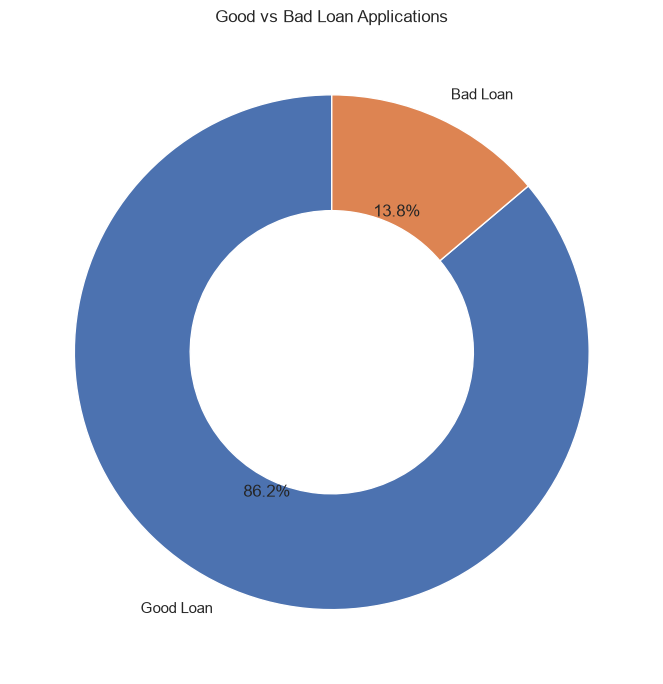

In [27]:
plot_data = loan_category_counts[loan_category_counts.index != "Other"]

plt.figure(figsize=(7, 7))
plt.pie(
    plot_data.values,
    labels=plot_data.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)
plt.title("Good vs Bad Loan Applications")
plt.tight_layout()
plt.show()

## 24. Good vs Bad Loan percentage

**What are we calculating?**

We calculate the percentage of total applications represented by Good Loans and Bad Loans.

This is useful for risk monitoring because a rising Bad Loan percentage can indicate portfolio deterioration.

In [28]:
loan_quality_summary = (
    df.groupby("LOAN_CATEGORY")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Amount_Received=("TOTAL_PAYMENT", "sum")
      )
)

loan_quality_summary["Application_Pct"] = (
    loan_quality_summary["Applications"] / len(df) * 100
).round(2)

display(loan_quality_summary)

,Applications,Funded_Amount,Amount_Received,Application_Pct
LOAN_CATEGORY,,,,
Bad Loan,5333,65532225,37284763,13.82
Good Loan,33243,370224850,435786170,86.18


# Loan Status Analysis

## 25. Loan-status distribution

**Business question:** What is the current status of the loan portfolio?

This supports the "Loan Status wise Loan Applications" visual from the problem statement.

In [29]:
status_summary = (
    df.groupby("LOAN_STATUS")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Amount_Received=("TOTAL_PAYMENT", "sum")
      )
      .sort_values("Applications", ascending=False)
)

display(status_summary)

,Applications,Funded_Amount,Amount_Received
LOAN_STATUS,,,
Fully Paid,32145,351358350,411586256
Charged Off,5333,65532225,37284763
Current,1098,18866500,24199914


## 26. Visualization — Applications by Loan Status

**Why?**

A bar chart makes the volume of each status easy to compare.

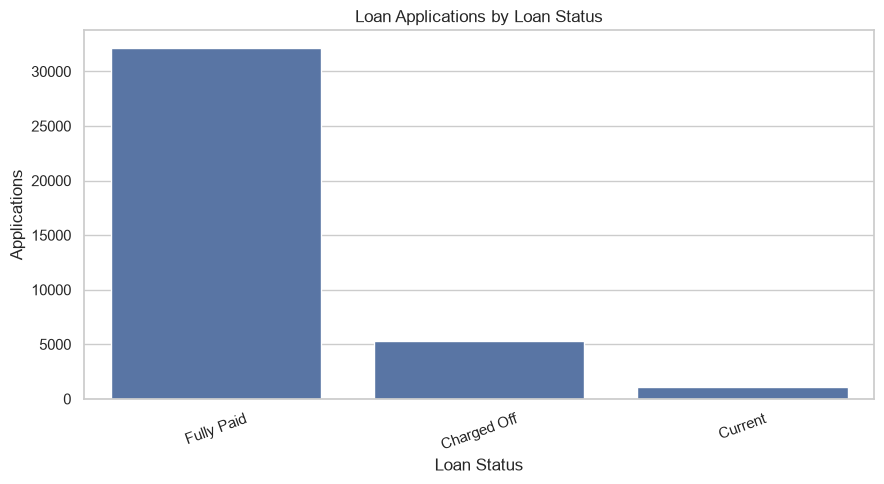

In [30]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=status_summary.reset_index(),
    x="LOAN_STATUS",
    y="Applications"
)
plt.title("Loan Applications by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Applications")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 27. Visualization — Funded Amount vs Amount Received by Loan Status

**Business question:** How much was funded versus how much was received for each loan status?

This directly supports the Summary dashboard requirement.

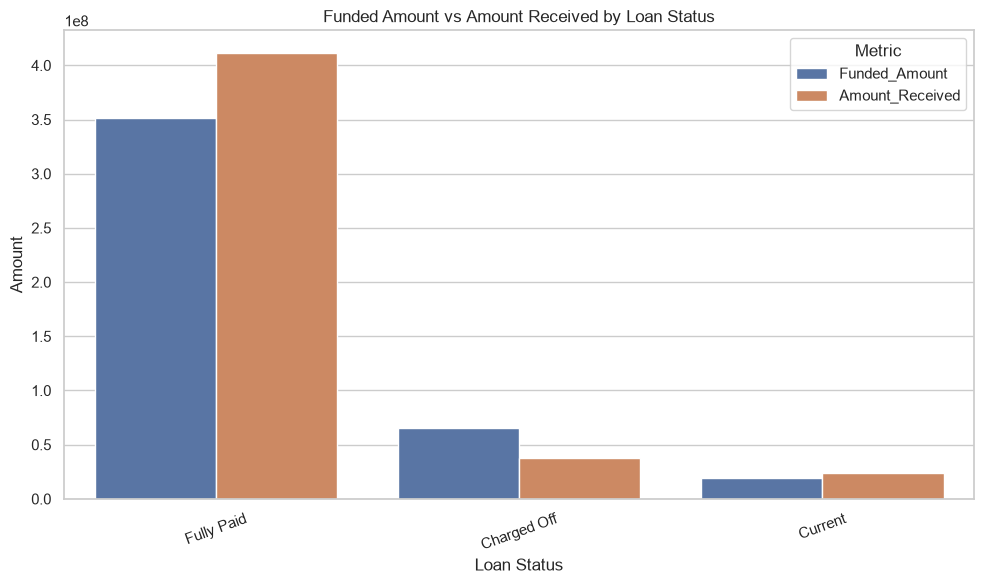

In [31]:
status_money = status_summary.reset_index().melt(
    id_vars="LOAN_STATUS",
    value_vars=["Funded_Amount", "Amount_Received"],
    var_name="Metric",
    value_name="Amount"
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=status_money,
    x="LOAN_STATUS",
    y="Amount",
    hue="Metric"
)
plt.title("Funded Amount vs Amount Received by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Amount")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Risk Analysis

## 28. Average Interest Rate by Loan Status

**Business question:** Do interest rates differ across loan statuses?

This helps connect pricing with portfolio performance and supports the required Summary visual.

In [32]:
interest_by_status = (
    df.groupby("LOAN_STATUS", as_index=False)["INT_RATE"]
      .mean()
)

interest_by_status["Average_Interest_Rate_Pct"] = (
    interest_by_status["INT_RATE"] * 100
)

display(interest_by_status[["LOAN_STATUS", "Average_Interest_Rate_Pct"]])

,LOAN_STATUS,Average_Interest_Rate_Pct
0,Charged Off,13.88
1,Current,15.10
2,Fully Paid,11.64


## 29. Visualization — Average Interest Rate by Loan Status

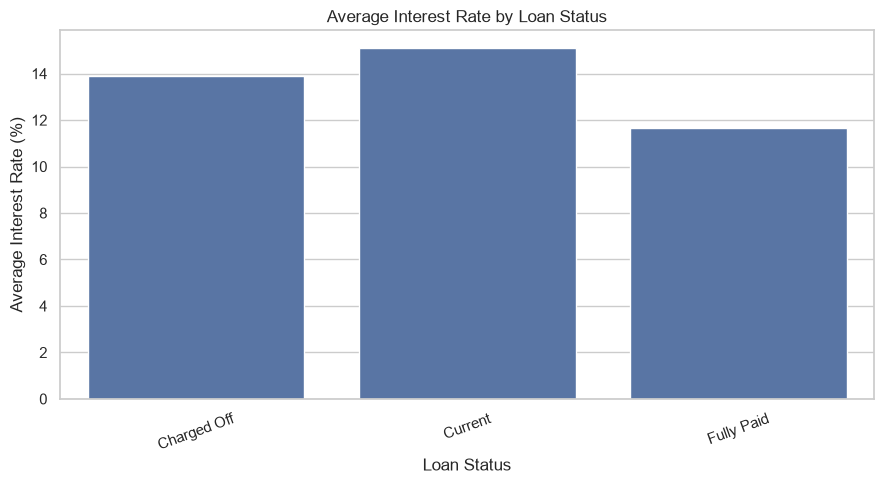

In [33]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=interest_by_status,
    x="LOAN_STATUS",
    y="Average_Interest_Rate_Pct"
)
plt.title("Average Interest Rate by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average Interest Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 30. Average DTI by Loan Status

**Business question:** Is borrower leverage different across loan statuses?

DTI is a useful borrower financial-health indicator and is explicitly required in the problem statement.

In [34]:
dti_by_status = (
    df.groupby("LOAN_STATUS", as_index=False)["DTI"]
      .mean()
)

dti_by_status["Average_DTI_Pct"] = dti_by_status["DTI"] * 100

display(dti_by_status[["LOAN_STATUS", "Average_DTI_Pct"]])

,LOAN_STATUS,Average_DTI_Pct
0,Charged Off,14.00
1,Current,14.72
2,Fully Paid,13.17


## 31. Visualization — Average DTI by Loan Status

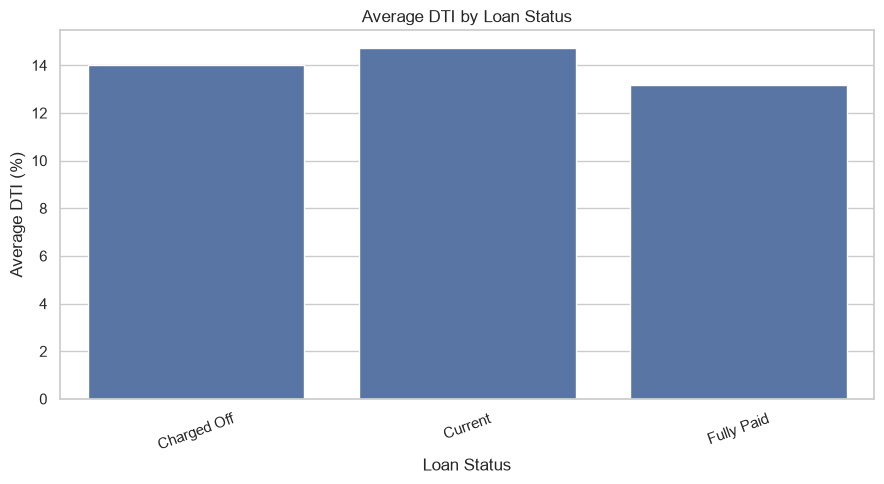

In [35]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=dti_by_status,
    x="LOAN_STATUS",
    y="Average_DTI_Pct"
)
plt.title("Average DTI by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Average DTI (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 32. Bad Loan Rate by Grade

**Business question:** Which credit grades carry greater portfolio risk?

Grade is the bank's overall risk classification. We calculate the percentage of loans charged off within each grade.

This adds a credit-risk perspective to the dashboard analysis.

In [36]:
grade_risk = (
    df.groupby("GRADE")
      .agg(
          Applications=("ID", "count"),
          Bad_Loans=("LOAN_CATEGORY", lambda x: (x == "Bad Loan").sum()),
          Funded_Amount=("LOAN_AMOUNT", "sum")
      )
      .reset_index()
)

grade_risk["Bad_Loan_Rate_Pct"] = (
    grade_risk["Bad_Loans"] / grade_risk["Applications"] * 100
).round(2)

grade_risk = grade_risk.sort_values("Bad_Loan_Rate_Pct", ascending=False)

display(grade_risk)

,GRADE,Applications,Bad_Loans,Funded_Amount,Bad_Loan_Rate_Pct
6,G,313,98,6348075,31.31
5,F,1028,311,18910450,30.25
4,E,2786,691,44165100,24.80
3,D,5182,1072,63920800,20.69
2,C,7904,1266,87456450,16.02
1,B,11674,1343,130703975,11.50
0,A,9689,552,84252225,5.70


## 33. Visualization — Bad Loan Rate by Grade

**Why?**

A grade-level risk chart highlights where credit quality is deteriorating and helps support lending-policy decisions.

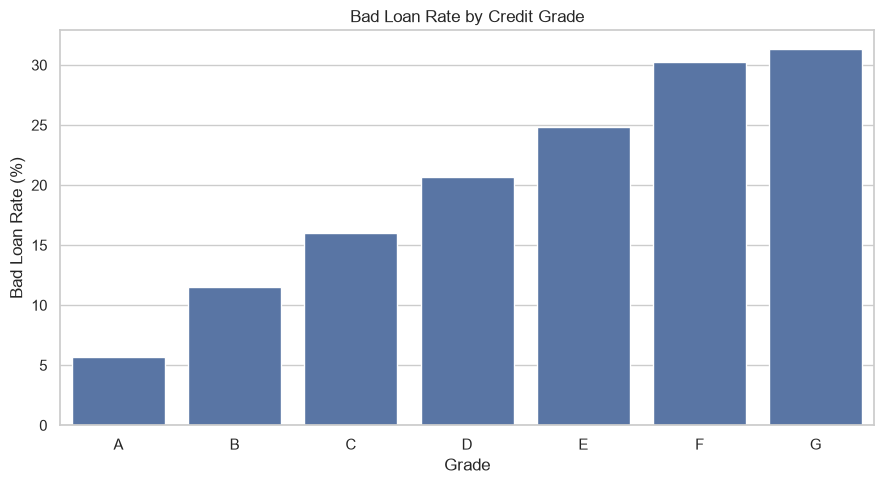

In [37]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=grade_risk.sort_values("GRADE"),
    x="GRADE",
    y="Bad_Loan_Rate_Pct"
)
plt.title("Bad Loan Rate by Credit Grade")
plt.xlabel("Grade")
plt.ylabel("Bad Loan Rate (%)")
plt.tight_layout()
plt.show()

# Dashboard 2 — Overview Analysis

## 34. Monthly Loan Applications

**Business question:** How did lending activity change over time?

We extract the month from `ISSUE_DATE` and count applications.

This directly corresponds to the required monthly loan-application line chart.

In [38]:
monthly = (
    df.assign(Month=df["ISSUE_DATE"].dt.to_period("M"))
      .groupby("Month")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Amount_Received=("TOTAL_PAYMENT", "sum")
      )
      .reset_index()
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()

display(monthly)

,Month,Applications,Funded_Amount,Amount_Received
0,2021-01-01,2332,25031650,27578836
1,2021-02-01,2279,24647825,27717745
2,2021-03-01,2627,28875700,32264400
3,2021-04-01,2755,29800800,32495533
4,2021-05-01,2911,31738350,33750523
5,2021-06-01,3184,34161475,36164533
6,2021-07-01,3366,35813900,38827220
7,2021-08-01,3441,38149600,42682218
8,2021-09-01,3536,40907725,43983948
9,2021-10-01,3796,44893800,49399567


## 35. Visualization — Monthly Loan Applications

**Why?**

A line chart reveals growth, decline and seasonal changes in loan demand.

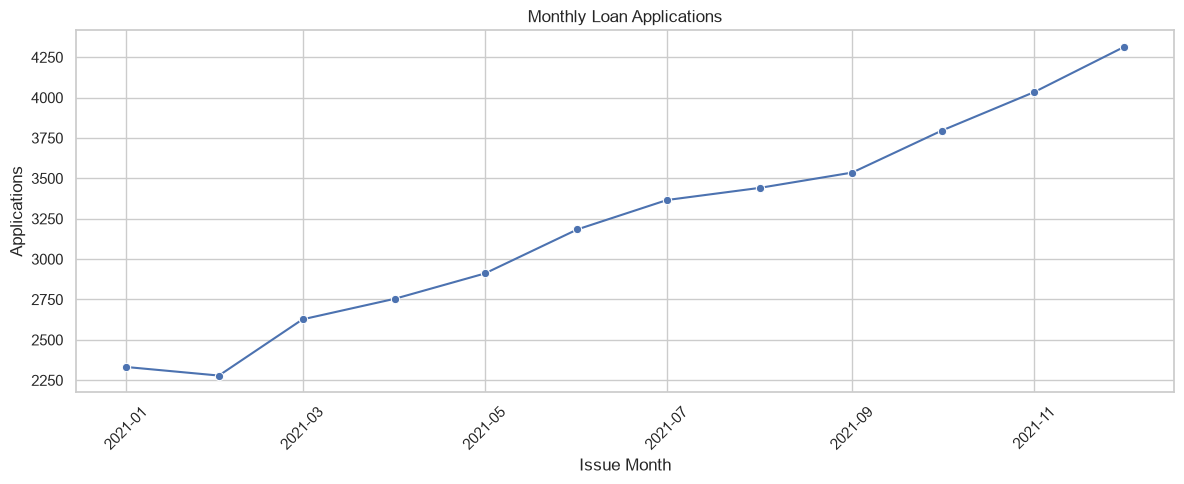

In [39]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x="Month",
    y="Applications",
    marker="o"
)
plt.title("Monthly Loan Applications")
plt.xlabel("Issue Month")
plt.ylabel("Applications")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 36. Monthly funded amount trend

**Why add this?**

Applications tell us volume, but funded amount tells us the monetary scale of lending.

This provides additional portfolio context while remaining consistent with the lending-performance objective.

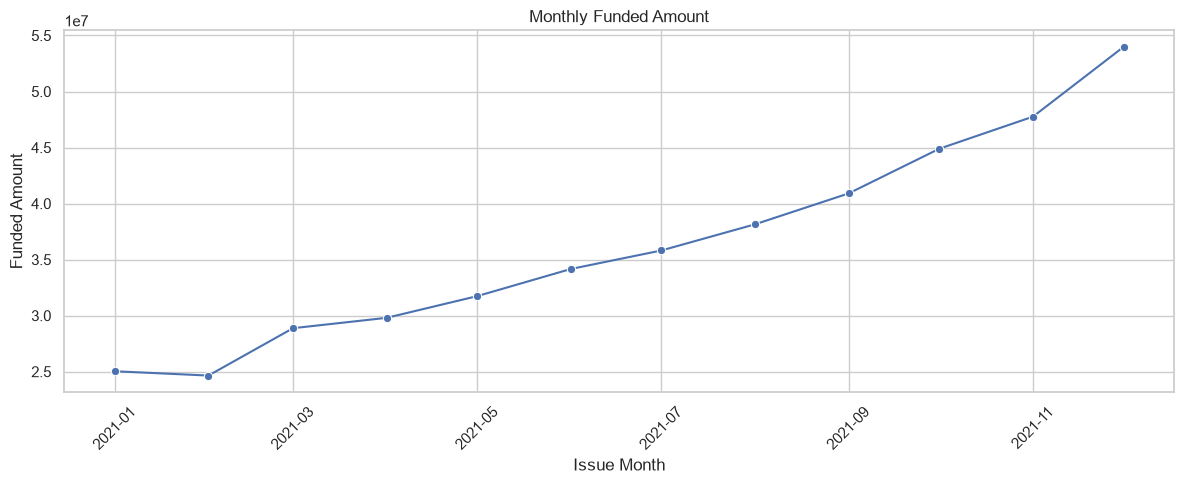

In [40]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly,
    x="Month",
    y="Funded_Amount",
    marker="o"
)
plt.title("Monthly Funded Amount")
plt.xlabel("Issue Month")
plt.ylabel("Funded Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 37. Loan Term Analysis

**Business question:** What repayment terms are most common?

The problem statement specifically requests a donut chart for loan-term analysis.

In [41]:
term_summary = (
    df.assign(TERM_CLEAN=df["TERM"].astype(str).str.strip())
      .groupby("TERM_CLEAN")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum")
      )
      .reset_index()
      .sort_values("Applications", ascending=False)
)

display(term_summary)

,TERM_CLEAN,Applications,Funded_Amount
0,36 months,28237,273041225
1,60 months,10339,162715850


## 38. Visualization — Loan Term Donut

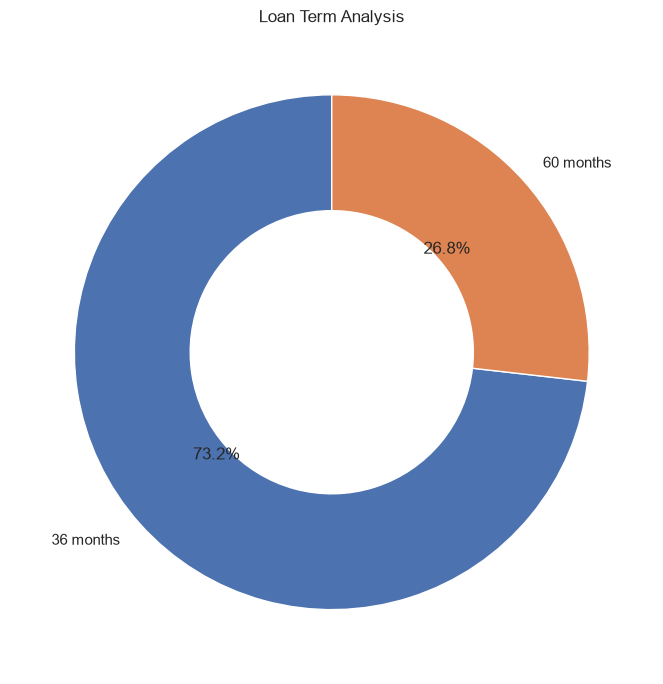

In [42]:
plt.figure(figsize=(7, 7))
plt.pie(
    term_summary["Applications"],
    labels=term_summary["TERM_CLEAN"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)
plt.title("Loan Term Analysis")
plt.tight_layout()
plt.show()

## 39. Home Ownership Analysis

**Business question:** How are borrowers distributed by home ownership?

This corresponds to the required Home Ownership bar chart.

In [43]:
home_summary = (
    df.groupby("HOME_OWNERSHIP")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Bad_Loans=("LOAN_CATEGORY", lambda x: (x == "Bad Loan").sum())
      )
      .reset_index()
)

home_summary["Bad_Loan_Rate_Pct"] = (
    home_summary["Bad_Loans"] / home_summary["Applications"] * 100
).round(2)

display(home_summary.sort_values("Applications", ascending=False))

,HOME_OWNERSHIP,Applications,Funded_Amount,Bad_Loans,Bad_Loan_Rate_Pct
4,RENT,18439,185768475,2687,14.57
0,MORTGAGE,17198,219329150,2231,12.97
3,OWN,2838,29597675,397,13.99
2,OTHER,98,1044975,18,18.37
1,NONE,3,16800,0,0.00


## 40. Visualization — Home Ownership

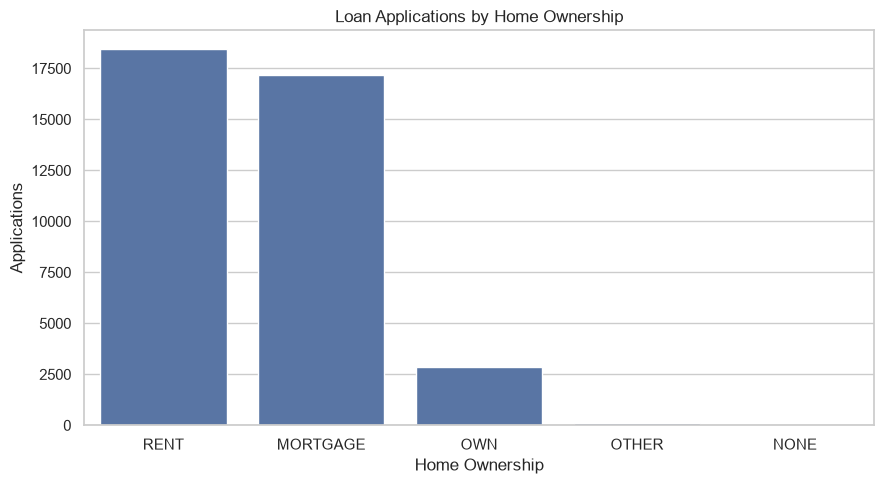

In [44]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=home_summary.sort_values("Applications", ascending=False),
    x="HOME_OWNERSHIP",
    y="Applications"
)
plt.title("Loan Applications by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Applications")
plt.tight_layout()
plt.show()

## 41. Loan Purpose Breakdown

**Business question:** Why are customers borrowing?

The problem statement requires a treemap for loan-purpose analysis.

In [45]:
purpose_summary = (
    df.groupby("PURPOSE")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Amount_Received=("TOTAL_PAYMENT", "sum")
      )
      .reset_index()
      .sort_values("Applications", ascending=False)
)

display(purpose_summary)

,PURPOSE,Applications,Funded_Amount,Amount_Received
0,Debt consolidation,18214,232459675,253801871
2,credit card,4998,58885175,65214084
9,other,3824,31155750,33289676
4,home improvement,2876,33350775,36380930
6,major purchase,2110,17251600,18676927
11,small business,1776,24123100,23814817
1,car,1497,10223575,11324914
13,wedding,928,9225800,10266856
7,medical,667,5533225,5851372
8,moving,559,3748125,3999899


## 42. Visualization — Loan Purpose Treemap

**Why a treemap?**

A treemap shows both the number and relative importance of purposes in a compact visual.

The rectangle size represents applications.

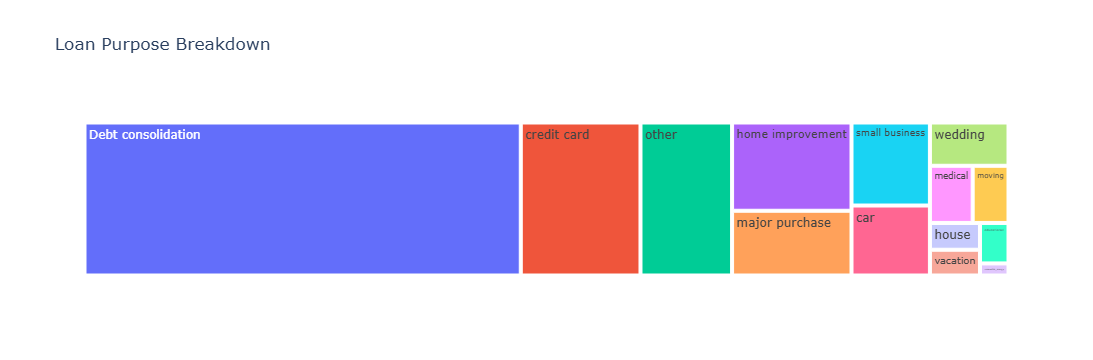

In [46]:
fig = px.treemap(
    purpose_summary,
    path=["PURPOSE"],
    values="Applications",
    title="Loan Purpose Breakdown"
)

fig.show()

## 43. Regional Analysis by State

**Business question:** Where is the loan portfolio concentrated?

We aggregate applications and funded amount by borrower state.

This creates the data required for the regional analysis visual.

In [47]:
state_summary = (
    df.groupby("ADDRESS_STATE")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Bad_Loans=("LOAN_CATEGORY", lambda x: (x == "Bad Loan").sum())
      )
      .reset_index()
)

state_summary["Bad_Loan_Rate_Pct"] = (
    state_summary["Bad_Loans"] / state_summary["Applications"] * 100
).round(2)

display(state_summary.sort_values("Applications", ascending=False).head(15))

,ADDRESS_STATE,Applications,Funded_Amount,Bad_Loans,Bad_Loan_Rate_Pct
4,CA,6894,78484125,1057,15.33
33,NY,3701,42077050,468,12.65
9,FL,2773,30046125,479,17.27
42,TX,2664,31236650,301,11.30
30,NJ,1822,21657475,273,14.98
14,IL,1486,17124225,192,12.92
37,PA,1482,15826525,169,11.40
44,VA,1375,15982650,170,12.36
10,GA,1355,15480325,207,15.28
19,MA,1310,15051000,150,11.45


## 44. Visualization — Regional Analysis Map

**Why?**

The map shows the geographic distribution of applications across U.S. states.

This corresponds to the Filled Map requirement in the problem statement.

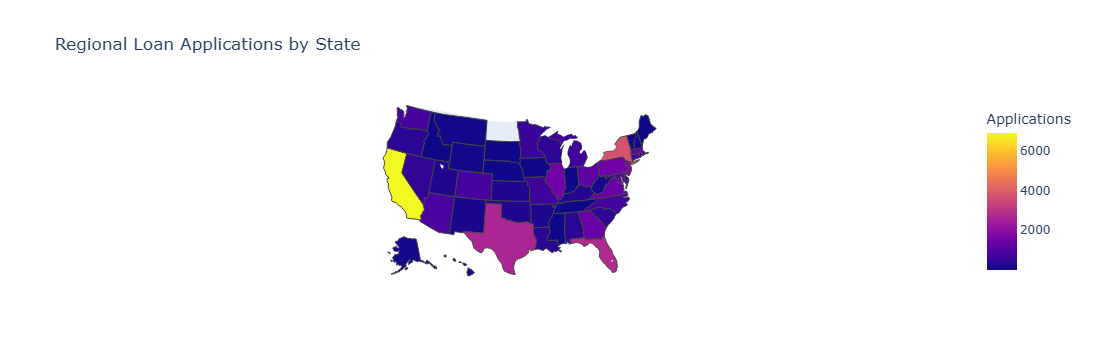

In [48]:
fig = px.choropleth(
    state_summary,
    locations="ADDRESS_STATE",
    locationmode="USA-states",
    color="Applications",
    scope="usa",
    hover_name="ADDRESS_STATE",
    hover_data={
        "Applications": True,
        "Funded_Amount": ":,.0f",
        "Bad_Loan_Rate_Pct": ":.2f"
    },
    title="Regional Loan Applications by State"
)

fig.show()

## 45. Top states by funded amount

**Why?**

The map shows geographic distribution, while this table makes the highest-funded markets immediately identifiable.

In [49]:
top_states = (
    state_summary
    .sort_values("Funded_Amount", ascending=False)
    .head(10)
)

display(top_states)

,ADDRESS_STATE,Applications,Funded_Amount,Bad_Loans,Bad_Loan_Rate_Pct
4,CA,6894,78484125,1057,15.33
33,NY,3701,42077050,468,12.65
42,TX,2664,31236650,301,11.30
9,FL,2773,30046125,479,17.27
30,NJ,1822,21657475,273,14.98
14,IL,1486,17124225,192,12.92
44,VA,1375,15982650,170,12.36
37,PA,1482,15826525,169,11.40
10,GA,1355,15480325,207,15.28
19,MA,1310,15051000,150,11.45


# Additional Portfolio Insights

## 46. Purpose-level risk analysis

**Business question:** Which borrowing purposes have the highest Bad Loan rate?

This combines business purpose with credit-risk performance.

In [50]:
purpose_risk = (
    df.groupby("PURPOSE")
      .agg(
          Applications=("ID", "count"),
          Bad_Loans=("LOAN_CATEGORY", lambda x: (x == "Bad Loan").sum()),
          Funded_Amount=("LOAN_AMOUNT", "sum")
      )
      .reset_index()
)

purpose_risk["Bad_Loan_Rate_Pct"] = (
    purpose_risk["Bad_Loans"] / purpose_risk["Applications"] * 100
).round(2)

display(
    purpose_risk.sort_values(
        ["Bad_Loan_Rate_Pct", "Applications"],
        ascending=[False, False]
    )
)

,PURPOSE,Applications,Bad_Loans,Funded_Amount,Bad_Loan_Rate_Pct
11,small business,1776,455,24123100,25.62
10,renewable_energy,94,17,845750,18.09
3,educational,315,50,2161650,15.87
5,house,366,57,4824925,15.57
9,other,3824,587,31155750,15.35
8,moving,559,84,3748125,15.03
7,medical,667,100,5533225,14.99
0,Debt consolidation,18214,2651,232459675,14.55
12,vacation,352,50,1967950,14.20
4,home improvement,2876,327,33350775,11.37


## 47. Grade-level portfolio concentration

**Why?**

We compare the number of applications and funded amount by grade.

This helps distinguish between high-volume grades and high-risk grades.

grade_summary = (
    df.groupby("GRADE")
      .agg(
          Applications=("ID", "count"),
          Funded_Amount=("LOAN_AMOUNT", "sum"),
          Amount_Received=("TOTAL_PAYMENT", "sum")
      )
      .reset_index()
)

grade_summary["Application_Share_Pct"] = (
    grade_summary["Applications"] / len(df) * 100
).round(2)

display(grade_summary.sort_values("Applications", ascending=False))

## 48. Final portfolio summary

**What are we doing?**

We bring the most important outputs into one table for final validation against the Power BI dashboard.

The purpose is not to duplicate Power BI, but to verify that Python, SQL and Power BI are using consistent business definitions.

In [52]:
final_summary = pd.DataFrame({
    "Metric": [
        "Applications",
        "Funded Amount",
        "Amount Received",
        "Average Interest Rate",
        "Average DTI",
        "Good Loan Applications",
        "Bad Loan Applications"
    ],
    "Value": [
        f"{len(df):,}",
        f"${df['LOAN_AMOUNT'].sum():,.0f}",
        f"${df['TOTAL_PAYMENT'].sum():,.0f}",
        f"{df['INT_RATE'].mean() * 100:.2f}%",
        f"{df['DTI'].mean() * 100:.2f}%",
        f"{(df['LOAN_CATEGORY'] == 'Good Loan').sum():,}",
        f"{(df['LOAN_CATEGORY'] == 'Bad Loan').sum():,}"
    ]
})

display(final_summary)

,Metric,Value
0,Applications,"38,576"
1,Funded Amount,"$435,757,075"
2,Amount Received,"$473,070,933"
3,Average Interest Rate,12.05%
4,Average DTI,13.33%
5,Good Loan Applications,"33,243"
6,Bad Loan Applications,"5,333"


# 49. Analyst conclusion

After running the notebook, use the calculated outputs to write the final business conclusion.

Focus on:

1. Overall lending volume and funded amount
2. Repayment amount relative to funding
3. Good vs Bad Loan composition
4. Loan-status concentration
5. Interest-rate differences across statuses
6. DTI differences across statuses
7. High-risk grades
8. Monthly lending trend
9. Geographic concentration
10. Major loan purposes
11. Loan-term and home-ownership patterns

Do **not** write conclusions before running the notebook. The raw data should determine the final findings.

# Visualization-to-Problem-Statement Mapping

| Problem Statement Requirement | Python Output |
|---|---|
| Total Loan Applications | KPI cells 17–22 |
| Total Funded Amount | KPI cells 18–22 |
| Total Amount Received | KPI cells 19–22 |
| Average Interest Rate | KPI cells 20–22 |
| Average DTI | KPI cells 21–22 |
| Good Loan Applications | Cells 23–25 |
| Bad Loan Applications | Cells 23–25 |
| Funded vs Repayment by Loan Status | Cell 28 |
| Loan Status-wise Applications | Cell 27 |
| Average Interest Rate by Loan Status | Cells 29–30 |
| Average DTI by Loan Status | Cells 31–32 |
| Monthly Loan Applications | Cells 35–36 |
| Regional Analysis | Cells 44–46 |
| Loan Term Analysis | Cells 38–39 |
| Home Ownership Analysis | Cells 40–41 |
| Loan Purpose Breakdown | Cells 42–43 |
| Risk/Grade Analysis | Cells 33–34 and 48 |

# Final validation checklist

Before using the Python results in your project:

- [ ] Raw row count matches the source dataset
- [ ] Duplicate loan IDs are checked
- [ ] Missing values are reviewed
- [ ] Dates are converted correctly
- [ ] `INT_RATE` and `DTI` are displayed as percentages
- [ ] Good Loan = Fully Paid / Current
- [ ] Bad Loan = Charged Off
- [ ] KPI values are compared with SQL
- [ ] KPI values are compared with Power BI
- [ ] Monthly totals reconcile
- [ ] State totals reconcile
- [ ] No conclusions are written from unvalidated numbers

In [53]:
output_path = DATA_PATH.parent / "Financial_loan_data_cleaned.xlsx"
df.to_excel(output_path, index=False)

print(f"Cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Saved to: {output_path}")

Cleaned dataset: 38,576 rows × 24 columns
Saved to: C:\Users\Deepak\Documents\Deepak Documents\PROJECTS\BANK LOAN ANALYTICS DASHBOARD END TO END PROJECT USING POWER BI\Financial_loan_data_cleaned.xlsx


In [64]:
!pip install mysql-connector-python

# 2. Connect Python to MySQL

In [65]:
import mysql.connector
import pandas as pd

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="bank_loan"
)

cursor = conn.cursor()

print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [66]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(38576, 24)
['ISSUE_DATE', 'ID', 'PURPOSE', 'VERIFICATION_STATUS', 'GRADE', 'HOME_OWNERSHIP', 'ADDRESS_STATE', 'LOAN_STATUS', 'EMP_LENGTH', 'EMP_TITLE', 'LAST_CREDIT_PULL_DATE', 'LAST_PAYMENT_DATE', 'NEXT_PAYMENT_DATE', 'MEMBER_ID', 'SUB_GRADE', 'TERM', 'ANNUAL_INCOME', 'DTI', 'INSTALLMENT', 'INT_RATE', 'LOAN_AMOUNT', 'TOTAL_ACC', 'TOTAL_PAYMENT', 'LOAN_CATEGORY']
ISSUE_DATE               datetime64[us]
ID                                int64
PURPOSE                             str
VERIFICATION_STATUS                 str
GRADE                               str
HOME_OWNERSHIP                      str
ADDRESS_STATE                       str
LOAN_STATUS                         str
EMP_LENGTH                          str
EMP_TITLE                        object
LAST_CREDIT_PULL_DATE    datetime64[us]
LAST_PAYMENT_DATE        datetime64[us]
NEXT_PAYMENT_DATE        datetime64[us]
MEMBER_ID                         int64
SUB_GRADE                           str
TERM                             

In [67]:
def mysql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return "BIGINT"
    elif pd.api.types.is_float_dtype(dtype):
        return "DOUBLE"
    elif pd.api.types.is_bool_dtype(dtype):
        return "BOOLEAN"
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return "DATETIME"
    else:
        return "TEXT"


columns_sql = []

for column in df.columns:
    sql_type = mysql_type(df[column].dtype)
    columns_sql.append(f"`{column}` {sql_type}")

create_table_sql = f"""
CREATE TABLE IF NOT EXISTS loan_data_cleaned (
    {", ".join(columns_sql)}
)
"""

cursor.execute(create_table_sql)
conn.commit()

print("Table 'loan_data_cleaned' created successfully!")

Table 'loan_data_cleaned' created successfully!


In [68]:
# Replace NaN with None because MySQL understands None as NULL
df_mysql = df.where(pd.notnull(df), None)

columns = ", ".join([f"`{col}`" for col in df.columns])
placeholders = ", ".join(["%s"] * len(df.columns))

insert_sql = f"""
INSERT INTO loan_data_cleaned ({columns})
VALUES ({placeholders})
"""

for row in df_mysql.itertuples(index=False, name=None):
    cursor.execute(insert_sql, row)

conn.commit()

print(f"{len(df):,} rows loaded successfully!")

38,576 rows loaded successfully!


In [69]:
cursor.execute("SELECT COUNT(*) FROM loan_data_cleaned")

count = cursor.fetchone()[0]

print(f"Rows in MySQL: {count:,}")

Rows in MySQL: 38,576


In [70]:
cursor.execute("SELECT * FROM loan_data_cleaned LIMIT 5")

rows = cursor.fetchall()

for row in rows:
    print(row)

(datetime.datetime(2021, 1, 1, 0, 0), 1072053, 'car', 'Source Verified', 'E', 'RENT', 'CA', 'Fully Paid', '9 years', 'MKC Accounting', datetime.datetime(2021, 12, 14, 0, 0), datetime.datetime(2021, 1, 15, 0, 0), datetime.datetime(2021, 2, 15, 0, 0), 1288686, 'E1', ' 36 months', 48000.0, 0.0535, 109.43, 0.1864, 3000, 4, 3939, 'Good Loan')
(datetime.datetime(2021, 1, 1, 0, 0), 1068350, 'car', 'Verified', 'A', 'MORTGAGE', 'IL', 'Fully Paid', '10+ years', 'J&J Steel Inc', datetime.datetime(2021, 12, 14, 0, 0), datetime.datetime(2021, 1, 15, 0, 0), datetime.datetime(2021, 2, 15, 0, 0), 1302971, 'A1', ' 36 months', 83000.0, 0.0231, 106.53, 0.0603, 3500, 28, 3835, 'Good Loan')
(datetime.datetime(2021, 1, 5, 0, 0), 1069243, 'car', 'Not Verified', 'C', 'RENT', 'CA', 'Charged Off', '4 years', 'Chemat Technology Inc', datetime.datetime(2021, 12, 12, 0, 0), datetime.datetime(2021, 1, 9, 0, 0), datetime.datetime(2021, 2, 9, 0, 0), 1304116, 'C5', ' 36 months', 50000.0, 0.2088, 421.65, 0.1596, 12000,